In [1]:
from pathlib import Path

results_dir = Path("results")
figures_dir = Path("figures")

results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

model_path = results_dir / "best_transformer_model.pt"

print("Model path:", model_path)
print("Exists:", model_path.exists())

Model path: results\best_transformer_model.pt
Exists: True


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [3]:
DATA_DIR = Path("Sequential_Peptides")

train_df = pd.read_csv(DATA_DIR / "train_seqs.csv")

train_df.drop(
    columns=["Unnamed: 0"],
    errors="ignore",
    inplace=True
)

y_train = train_df["Label"].to_numpy(dtype=np.float32)

y_mean = y_train.mean()
y_std = y_train.std()

print("y_mean:", y_mean)
print("y_std:", y_std)

y_mean: 1.7387624
y_std: 0.21119417


In [4]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

PAD_INDEX = 0

AA_TO_TOKEN = {
    amino_acid: index + 1
    for index, amino_acid in enumerate(AMINO_ACIDS)
}

TOKEN_TO_AA = {
    token: amino_acid
    for amino_acid, token in AA_TO_TOKEN.items()
}

VOCAB_SIZE = len(AMINO_ACIDS) + 1
MAX_LENGTH = 10

print("VOCAB_SIZE:", VOCAB_SIZE)
print("MAX_LENGTH:", MAX_LENGTH)
print(AA_TO_TOKEN)

VOCAB_SIZE: 21
MAX_LENGTH: 10
{'A': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'V': 18, 'W': 19, 'Y': 20}


In [5]:
def encode_token_sequence(sequence: str):
    sequence = str(sequence).strip().upper()

    if len(sequence) == 0:
        raise ValueError("Empty peptide sequence encountered.")

    if len(sequence) > MAX_LENGTH:
        raise ValueError(f"Sequence is too long: {sequence}")

    token_ids = []

    for amino_acid in sequence:
        if amino_acid not in AA_TO_TOKEN:
            raise ValueError(f"Unexpected amino acid: {amino_acid}")

        token_ids.append(AA_TO_TOKEN[amino_acid])

    original_length = len(token_ids)

    padded_tokens = (
        token_ids
        + [PAD_INDEX] * (MAX_LENGTH - original_length)
    )

    return np.array(padded_tokens, dtype=np.int64), original_length

In [6]:
class TransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        max_length: int,
        embedding_dim: int = 64,
        num_heads: int = 4,
        num_layers: int = 2,
        feedforward_dim: int = 128,
        dropout_rate: float = 0.10
    ):
        super().__init__()

        if embedding_dim % num_heads != 0:
            raise ValueError(
                "embedding_dim must be divisible by num_heads."
            )

        self.token_embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_INDEX
        )

        self.position_embedding = nn.Embedding(
            num_embeddings=max_length,
            embedding_dim=embedding_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout_rate,
            activation="gelu",
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=num_layers
        )

        self.output_head = nn.Sequential(
            nn.LayerNorm(embedding_dim),
            nn.Linear(embedding_dim, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(64, 1)
        )

    def forward(
        self,
        token_ids: torch.Tensor,
        sequence_lengths: torch.Tensor
    ) -> torch.Tensor:
        batch_size, sequence_length = token_ids.shape

        position_ids = torch.arange(
            sequence_length,
            device=token_ids.device
        ).unsqueeze(0)

        token_features = self.token_embedding(token_ids)
        position_features = self.position_embedding(position_ids)

        embedded_tokens = token_features + position_features

        padding_mask = token_ids == PAD_INDEX

        encoded_tokens = self.transformer_encoder(
            embedded_tokens,
            src_key_padding_mask=padding_mask
        )

        non_padding_mask = (
            ~padding_mask
        ).unsqueeze(-1).type_as(encoded_tokens)

        summed_representation = (
            encoded_tokens * non_padding_mask
        ).sum(dim=1)

        valid_token_count = (
            sequence_lengths
            .unsqueeze(1)
            .clamp_min(1)
            .type_as(encoded_tokens)
        )

        pooled_representation = (
            summed_representation / valid_token_count
        )

        return self.output_head(pooled_representation)

In [7]:
transformer_model = TransformerRegressor(
    vocab_size=VOCAB_SIZE,
    max_length=MAX_LENGTH
).to(device)

state_dict = torch.load(
    model_path,
    map_location=device
)

transformer_model.load_state_dict(state_dict)

transformer_model.eval()

print("Transformer model loaded successfully.")

Transformer model loaded successfully.


In [8]:
def restore_original_scale(scaled_values: np.ndarray) -> np.ndarray:
    return scaled_values * y_std + y_mean


def predict_ap_from_sequences(sequences):
    token_arrays = []
    lengths = []

    for sequence in sequences:
        tokens, length = encode_token_sequence(sequence)
        token_arrays.append(tokens)
        lengths.append(length)

    token_tensor = torch.tensor(
        np.vstack(token_arrays),
        dtype=torch.long
    ).to(device)

    length_tensor = torch.tensor(
        np.array(lengths),
        dtype=torch.long
    ).to(device)

    transformer_model.eval()

    with torch.no_grad():
        scaled_predictions = transformer_model(
            token_tensor,
            length_tensor
        ).cpu().numpy().reshape(-1)

    return restore_original_scale(scaled_predictions)

In [9]:
def predict_ap_from_token_arrays(
    model,
    token_matrix,
    sequence_lengths,
    batch_size=1024
):
    token_tensor = torch.tensor(
        token_matrix,
        dtype=torch.long
    )

    length_tensor = torch.tensor(
        sequence_lengths,
        dtype=torch.long
    )

    dataset = TensorDataset(
        token_tensor,
        length_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    scaled_predictions = []

    model.eval()

    with torch.no_grad():
        for token_batch, length_batch in loader:
            token_batch = token_batch.to(device)
            length_batch = length_batch.to(device)

            prediction_batch = model(
                token_batch,
                length_batch
            )

            scaled_predictions.append(
                prediction_batch
                .cpu()
                .numpy()
                .reshape(-1)
            )

    scaled_predictions = np.concatenate(
        scaled_predictions
    )

    return restore_original_scale(
        scaled_predictions
    )

In [10]:
def scan_sequences_batch(
    sequences,
    model,
    batch_size=2048
):
    records = []
    mutant_token_arrays = []
    mutant_lengths = []

    original_predictions = {}

    original_token_arrays = []
    original_lengths = []

    for sequence in sequences:
        tokens, length = encode_token_sequence(sequence)
        original_token_arrays.append(tokens)
        original_lengths.append(length)

    original_token_arrays = np.vstack(original_token_arrays)
    original_lengths = np.array(original_lengths)

    original_ap_predictions = predict_ap_from_token_arrays(
        model,
        original_token_arrays,
        original_lengths,
        batch_size=batch_size
    )

    for sequence, original_prediction in zip(
        sequences,
        original_ap_predictions
    ):
        original_predictions[sequence] = original_prediction

    for sequence in sequences:
        original_tokens, original_length = encode_token_sequence(
            sequence
        )

        original_prediction = original_predictions[
            sequence
        ]

        for position in range(original_length):
            original_token = int(
                original_tokens[position]
            )

            original_amino_acid = TOKEN_TO_AA[
                original_token
            ]

            for mutant_amino_acid, mutant_token in AA_TO_TOKEN.items():
                if mutant_token == original_token:
                    continue

                mutant_tokens = original_tokens.copy()
                mutant_tokens[position] = mutant_token

                mutant_sequence_list = list(sequence)
                mutant_sequence_list[position] = mutant_amino_acid
                mutant_sequence = "".join(mutant_sequence_list)

                mutant_token_arrays.append(mutant_tokens)
                mutant_lengths.append(original_length)

                records.append({
                    "sequence": sequence,
                    "mutant_sequence": mutant_sequence,
                    "position": position + 1,
                    "original_amino_acid": original_amino_acid,
                    "mutant_amino_acid": mutant_amino_acid,
                    "original_prediction": original_prediction
                })

    mutant_token_arrays = np.vstack(mutant_token_arrays)
    mutant_lengths = np.array(mutant_lengths)

    mutant_predictions = predict_ap_from_token_arrays(
        model,
        mutant_token_arrays,
        mutant_lengths,
        batch_size=batch_size
    )

    scan_df = pd.DataFrame(records)

    scan_df["mutant_prediction"] = mutant_predictions

    scan_df["delta_AP"] = (
        scan_df["mutant_prediction"]
        - scan_df["original_prediction"]
    )

    return scan_df

In [11]:
single_scan_df = scan_sequences_batch(
    ["KYYQY"],
    transformer_model,
    batch_size=512
)

display(single_scan_df.head())

print("Number of mutations:", len(single_scan_df))

C:\Users\yzy27\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:182.)
  output = torch._nested_tensor_from_mask(


,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
0,KYYQY,AYYQY,1,K,A,2.150085,2.088526,-0.061559
1,KYYQY,CYYQY,1,K,C,2.150085,2.212115,0.062030
2,KYYQY,DYYQY,1,K,D,2.150085,1.993164,-0.156922
3,KYYQY,EYYQY,1,K,E,2.150085,1.966080,-0.184005
4,KYYQY,FYYQY,1,K,F,2.150085,2.227230,0.077145


Number of mutations: 95


In [12]:
display(
    single_scan_df
    .sort_values("delta_AP", ascending=False)
    .head(10)
)

,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
61,KYYQY,KYYFY,4,Q,F,2.150085,2.325248,0.175162
75,KYYQY,KYYYY,4,Q,Y,2.150085,2.310504,0.160419
74,KYYQY,KYYWY,4,Q,W,2.150085,2.295614,0.145529
11,KYYQY,PYYQY,1,K,P,2.150085,2.269747,0.119661
64,KYYQY,KYYIY,4,Q,I,2.150085,2.269012,0.118927
66,KYYQY,KYYLY,4,Q,L,2.150085,2.268794,0.118709
69,KYYQY,KYYPY,4,Q,P,2.150085,2.264725,0.114640
67,KYYQY,KYYMY,4,Q,M,2.150085,2.263522,0.113437
73,KYYQY,KYYVY,4,Q,V,2.150085,2.261318,0.111233
58,KYYQY,KYYCY,4,Q,C,2.150085,2.256474,0.106389


In [13]:
display(
    single_scan_df
    .sort_values("delta_AP", ascending=True)
    .head(10)
)

,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
90,KYYQY,KYYQR,5,Y,R,2.150085,1.847077,-0.303009
52,KYYQY,KYRQY,3,Y,R,2.150085,1.847713,-0.302372
84,KYYQY,KYYQK,5,Y,K,2.150085,1.863347,-0.286738
33,KYYQY,KRYQY,2,Y,R,2.150085,1.871843,-0.278242
46,KYYQY,KYKQY,3,Y,K,2.150085,1.879200,-0.270886
43,KYYQY,KYGQY,3,Y,G,2.150085,1.886966,-0.263119
51,KYYQY,KYQQY,3,Y,Q,2.150085,1.899945,-0.250141
27,KYYQY,KKYQY,2,Y,K,2.150085,1.914391,-0.235694
49,KYYQY,KYNQY,3,Y,N,2.150085,1.919574,-0.230511
89,KYYQY,KYYQQ,5,Y,Q,2.150085,1.919718,-0.230367


In [14]:
analysis_df = pd.read_csv(
    results_dir / "test_error_analysis_all_models.csv"
)

hard_sequences = (
    analysis_df
    .sort_values(
        "Transformer_absolute_error",
        ascending=False
    )
    ["Feature"]
    .head(10)
    .tolist()
)

hard_scan_df = scan_sequences_batch(
    hard_sequences,
    transformer_model,
    batch_size=2048
)

display(hard_scan_df.head())
print("Number of mutation records:", len(hard_scan_df))

,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
0,CAAPP,AAAPP,1,C,A,1.435567,1.235646,-0.199921
1,CAAPP,DAAPP,1,C,D,1.435567,1.067696,-0.367871
2,CAAPP,EAAPP,1,C,E,1.435567,1.057681,-0.377886
3,CAAPP,FAAPP,1,C,F,1.435567,1.848399,0.412832
4,CAAPP,GAAPP,1,C,G,1.435567,1.201204,-0.234363


Number of mutation records: 1045


In [15]:
hard_scan_count = (
    hard_scan_df
    .groupby("sequence")
    .size()
    .reset_index(name="mutation_count")
)

hard_scan_count["expected_count"] = (
    hard_scan_count["sequence"].str.len() * 19
)

assert (
    hard_scan_count["mutation_count"]
    == hard_scan_count["expected_count"]
).all()

In [16]:
hard_scan_df.to_csv(
    results_dir / "mutation_scan_hard_sequences.csv",
    index=False
)

In [17]:
display(
    hard_scan_df
    .sort_values("delta_AP", ascending=False)
    .head(20)
)

,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
340,VQDMP,VQWMP,3,D,W,1.340870,2.044441,0.703571
758,AEGCL,AWGCL,2,E,W,1.243958,1.944327,0.700369
55,CAAPP,CAWPP,3,A,W,1.435567,2.113757,0.678190
744,AEGCL,AFGCL,2,E,F,1.243958,1.909431,0.665473
326,VQDMP,VQFMP,3,D,F,1.340870,1.996600,0.655730
41,CAAPP,CAFPP,3,A,F,1.435567,2.078968,0.643401
777,AEGCL,AEWCL,3,G,W,1.243958,1.880688,0.636731
759,AEGCL,AYGCL,2,E,Y,1.243958,1.875744,0.631787
341,VQDMP,VQYMP,3,D,Y,1.340870,1.964284,0.623414
56,CAAPP,CAYPP,3,A,Y,1.435567,2.058790,0.623223


In [18]:
display(
    hard_scan_df
    .sort_values("delta_AP", ascending=True)
    .head(20)
)

,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
432,IPYGK,IPRGK,3,Y,R,1.935402,1.089076,-0.846326
429,IPYGK,IPNGK,3,Y,N,1.935402,1.108991,-0.826411
426,IPYGK,IPKGK,3,Y,K,1.935402,1.125362,-0.810040
431,IPYGK,IPQGK,3,Y,Q,1.935402,1.213560,-0.721842
418,IPYGK,IPAGK,3,Y,A,1.935402,1.271456,-0.663946
423,IPYGK,IPGGK,3,Y,G,1.935402,1.393302,-0.542100
421,IPYGK,IPEGK,3,Y,E,1.935402,1.411022,-0.524380
182,AADGF,AADGP,5,F,P,1.544607,1.048023,-0.496584
174,AADGF,AADGE,5,F,E,1.544607,1.049223,-0.495384
180,AADGF,AADGM,5,F,M,1.544607,1.050950,-0.493657


In [19]:
sampled_sequences = (
    analysis_df
    .sample(
        n=500,
        random_state=42
    )
    ["Feature"]
    .tolist()
)

print("Number of sampled sequences:", len(sampled_sequences))

Number of sampled sequences: 500


In [20]:
global_scan_df = scan_sequences_batch(
    sampled_sequences,
    transformer_model,
    batch_size=4096
)

print("Number of mutation records:", len(global_scan_df))
display(global_scan_df.head())

Number of mutation records: 72162


,sequence,mutant_sequence,position,original_amino_acid,mutant_amino_acid,original_prediction,mutant_prediction,delta_AP
0,KFASSPKNVM,AFASSPKNVM,1,K,A,1.713078,1.712972,-0.000106
1,KFASSPKNVM,CFASSPKNVM,1,K,C,1.713078,1.774728,0.061650
2,KFASSPKNVM,DFASSPKNVM,1,K,D,1.713078,1.709832,-0.003246
3,KFASSPKNVM,EFASSPKNVM,1,K,E,1.713078,1.714578,0.001500
4,KFASSPKNVM,FFASSPKNVM,1,K,F,1.713078,1.837098,0.124020


In [21]:
global_scan_df.to_csv(
    results_dir / "mutation_scan_random_500.csv",
    index=False
)

In [22]:
mutant_effect_df = (
    global_scan_df
    .groupby("mutant_amino_acid")["delta_AP"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

display(mutant_effect_df)

,mutant_amino_acid,count,mean,median,std
18,W,3596,0.130245,0.107176,0.104034
4,F,3585,0.110683,0.092511,0.097219
19,Y,3655,0.101817,0.085422,0.096898
6,H,3608,0.060035,0.048294,0.097177
7,I,3591,0.027550,0.019936,0.083148
9,L,3603,0.025625,0.018375,0.082941
17,V,3601,0.018293,0.011922,0.083034
1,C,3598,0.014743,0.009108,0.082313
10,M,3622,0.009792,0.005327,0.084392
12,P,3612,0.008391,0.005731,0.087920


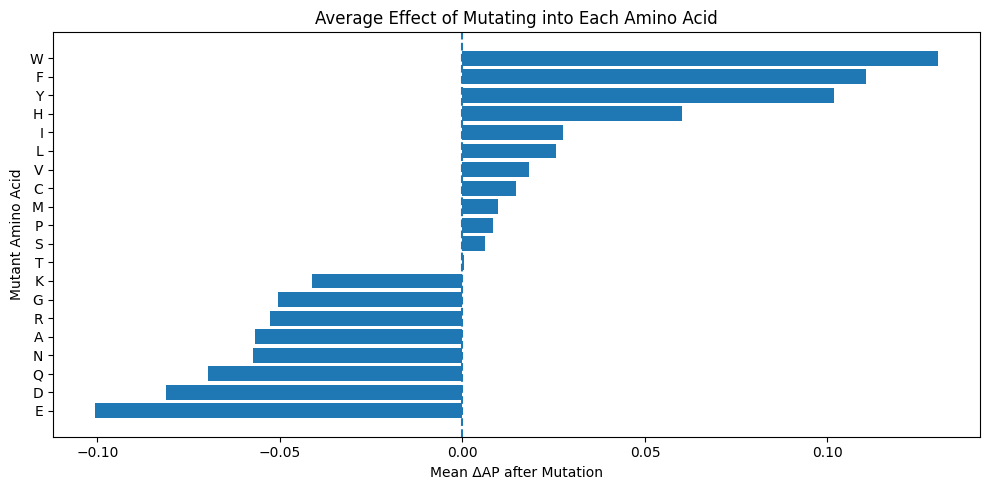

In [23]:
plt.figure(figsize=(10, 5))

plot_data = mutant_effect_df.sort_values("mean")

plt.barh(
    plot_data["mutant_amino_acid"],
    plot_data["mean"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Mean ΔAP after Mutation")
plt.ylabel("Mutant Amino Acid")
plt.title("Average Effect of Mutating into Each Amino Acid")

plt.tight_layout()

plt.savefig(
    figures_dir / "mutation_effect_by_mutant_amino_acid.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [24]:
original_effect_df = (
    global_scan_df
    .groupby("original_amino_acid")["delta_AP"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
    .sort_values("mean", ascending=True)
)

display(original_effect_df)

,original_amino_acid,count,mean,median,std
18,W,3838,-0.125219,-0.103445,0.101990
4,F,4047,-0.108946,-0.090012,0.098588
19,Y,2717,-0.102466,-0.081541,0.101231
6,H,3610,-0.056733,-0.044247,0.096323
7,I,3933,-0.026930,-0.018649,0.086849
9,L,3705,-0.026554,-0.016492,0.085605
17,V,3743,-0.016078,-0.012957,0.082545
1,C,3800,-0.016059,-0.008887,0.096249
15,S,3439,-0.011111,-0.001461,0.091966
10,M,3344,-0.008999,-0.005676,0.089553


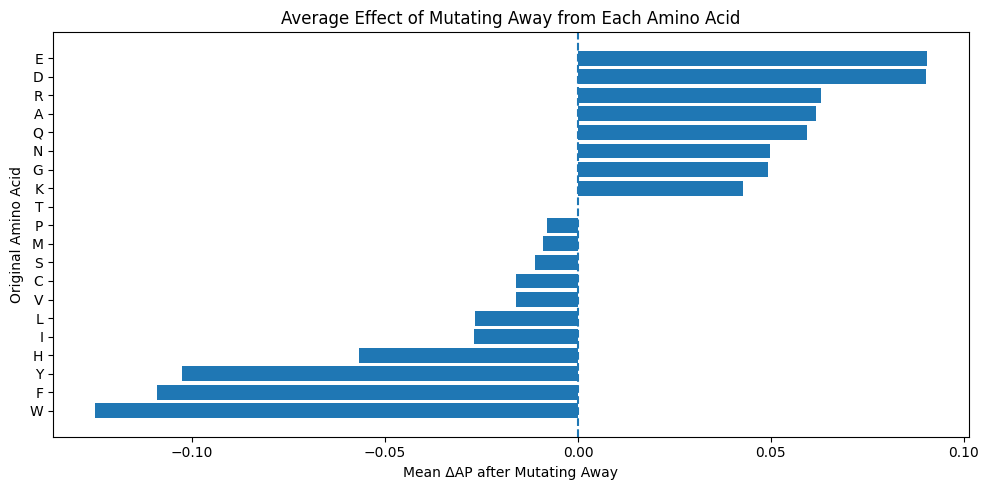

In [25]:
plt.figure(figsize=(10, 5))

plot_data = original_effect_df.sort_values("mean")

plt.barh(
    plot_data["original_amino_acid"],
    plot_data["mean"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Mean ΔAP after Mutating Away")
plt.ylabel("Original Amino Acid")
plt.title("Average Effect of Mutating Away from Each Amino Acid")

plt.tight_layout()

plt.savefig(
    figures_dir / "mutation_effect_by_original_amino_acid.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [26]:
mutation_matrix = (
    global_scan_df
    .groupby([
        "original_amino_acid",
        "mutant_amino_acid"
    ])["delta_AP"]
    .mean()
    .reset_index()
    .pivot(
        index="original_amino_acid",
        columns="mutant_amino_acid",
        values="delta_AP"
    )
    .reindex(
        index=AMINO_ACIDS,
        columns=AMINO_ACIDS
    )
)

display(mutation_matrix)

mutant_amino_acid,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
original_amino_acid,,,,,,,,,,,,,,,,,,,,
A,NaN,0.071166,-0.016202,-0.034033,0.165443,0.007449,0.115628,0.083601,0.022800,0.081956,0.066602,0.003476,0.064177,-0.008571,0.012744,0.062276,0.056581,0.074259,0.183607,0.158578
C,-0.079701,NaN,-0.103042,-0.125358,0.100590,-0.067565,0.054016,0.013411,-0.060322,0.011667,-0.007337,-0.077472,-0.008468,-0.091424,-0.070182,-0.004054,-0.009926,0.004857,0.121078,0.094113
D,0.030490,0.097351,NaN,-0.018584,0.196058,0.035326,0.145721,0.109903,0.053623,0.108340,0.092179,0.027763,0.091667,0.016458,0.042805,0.091197,0.084895,0.101154,0.218042,0.188975
E,0.033177,0.098146,0.018169,NaN,0.188439,0.038453,0.143684,0.109516,0.043493,0.107566,0.093081,0.031082,0.091482,0.020427,0.033298,0.090668,0.085634,0.100743,0.207906,0.182979
F,-0.159005,-0.090322,-0.183429,-0.202777,NaN,-0.151934,-0.045237,-0.078040,-0.134780,-0.079802,-0.095218,-0.158703,-0.097589,-0.170622,-0.144999,-0.098934,-0.104081,-0.087721,0.019839,-0.006619
G,-0.004420,0.061740,-0.020477,-0.039273,0.147408,NaN,0.097492,0.072793,-0.001409,0.070415,0.059004,-0.003928,0.058475,-0.016102,-0.012770,0.050283,0.045464,0.065447,0.164161,0.141048
H,-0.107818,-0.040703,-0.122060,-0.139561,0.045504,-0.101250,NaN,-0.029076,-0.094001,-0.031394,-0.045169,-0.106689,-0.045447,-0.119768,-0.104811,-0.048081,-0.053434,-0.037413,0.064434,0.038805
I,-0.081728,-0.012722,-0.104906,-0.122216,0.078481,-0.075639,0.033705,NaN,-0.059491,-0.001134,-0.017743,-0.082478,-0.018768,-0.093310,-0.070033,-0.019732,-0.025207,-0.009256,0.098599,0.071900
K,-0.018701,0.054915,-0.038433,-0.058910,0.148164,-0.008269,0.100354,0.066242,NaN,0.064107,0.047863,-0.013685,0.045596,-0.027166,-0.010788,0.048697,0.043213,0.058523,0.167965,0.141215


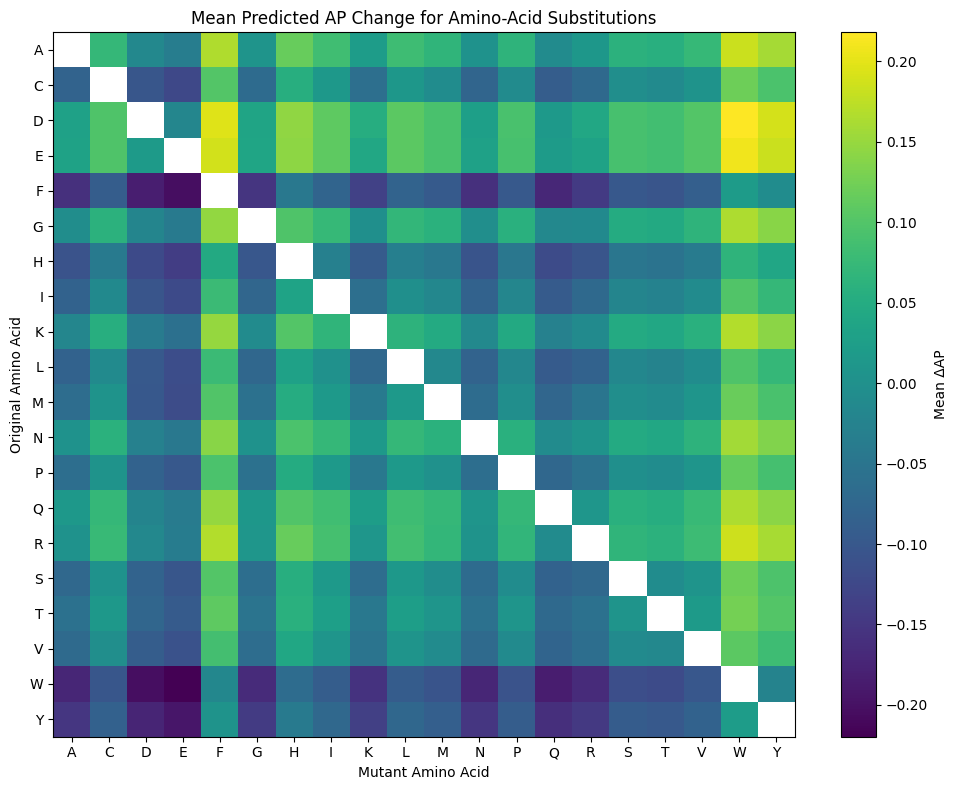

In [27]:
plt.figure(figsize=(10, 8))

plt.imshow(
    mutation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Mean ΔAP"
)

plt.xticks(
    ticks=range(len(AMINO_ACIDS)),
    labels=AMINO_ACIDS
)

plt.yticks(
    ticks=range(len(AMINO_ACIDS)),
    labels=AMINO_ACIDS
)

plt.xlabel("Mutant Amino Acid")
plt.ylabel("Original Amino Acid")
plt.title("Mean Predicted AP Change for Amino-Acid Substitutions")

plt.tight_layout()

plt.savefig(
    figures_dir / "mutation_effect_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [28]:
position_effect_df = (
    global_scan_df
    .groupby([
        "position",
        "mutant_amino_acid"
    ])["delta_AP"]
    .mean()
    .reset_index()
)

position_heatmap = (
    position_effect_df
    .pivot(
        index="mutant_amino_acid",
        columns="position",
        values="delta_AP"
    )
    .reindex(AMINO_ACIDS)
)

display(position_heatmap)

position,1,2,3,4,5,6,7,8,9,10
mutant_amino_acid,,,,,,,,,,
A,-0.062681,-0.055423,-0.072895,-0.066693,-0.048674,-0.047939,-0.048049,-0.046103,-0.045350,-0.061987
C,0.018678,0.019582,0.012322,0.013505,0.016033,0.018641,0.009060,0.009160,0.012304,0.005478
D,-0.125337,-0.094497,-0.094340,-0.087785,-0.070130,-0.055593,-0.058886,-0.052296,-0.052041,-0.062114
E,-0.135619,-0.118272,-0.114784,-0.109435,-0.095793,-0.075981,-0.073176,-0.068844,-0.070462,-0.076231
F,0.102145,0.110276,0.124563,0.115916,0.120942,0.109714,0.101192,0.096105,0.103515,0.094722
G,-0.062255,-0.045303,-0.061628,-0.048749,-0.045957,-0.045321,-0.046738,-0.043998,-0.043242,-0.058392
H,0.045815,0.059514,0.071701,0.064479,0.066351,0.062396,0.057764,0.053528,0.054945,0.044579
I,0.039798,0.038810,0.034270,0.026779,0.023493,0.022800,0.015104,0.015156,0.017758,0.012549
K,-0.012271,-0.030949,-0.042956,-0.048157,-0.066665,-0.047274,-0.043968,-0.043254,-0.031099,-0.050853


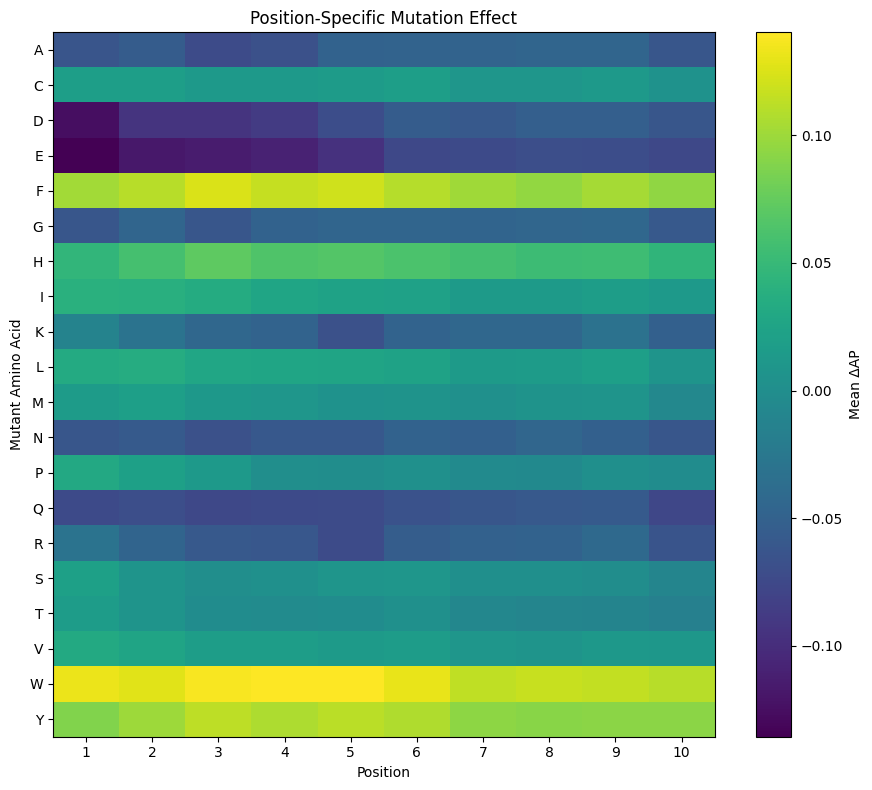

In [29]:
plt.figure(figsize=(9, 8))

plt.imshow(
    position_heatmap,
    aspect="auto"
)

plt.colorbar(
    label="Mean ΔAP"
)

plt.xticks(
    ticks=range(len(position_heatmap.columns)),
    labels=position_heatmap.columns
)

plt.yticks(
    ticks=range(len(position_heatmap.index)),
    labels=position_heatmap.index
)

plt.xlabel("Position")
plt.ylabel("Mutant Amino Acid")
plt.title("Position-Specific Mutation Effect")

plt.tight_layout()

plt.savefig(
    figures_dir / "position_specific_mutation_effect.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [30]:
sequence_to_true_ap = dict(
    zip(
        analysis_df["Feature"],
        analysis_df["Label"]
    )
)

global_scan_df["true_AP"] = (
    global_scan_df["sequence"]
    .map(sequence_to_true_ap)
)

global_scan_df["AP_group"] = pd.cut(
    global_scan_df["true_AP"],
    bins=[
        -np.inf,
        1.4,
        1.8,
        np.inf
    ],
    labels=[
        "Low AP",
        "Middle AP",
        "High AP"
    ]
)

In [31]:
mutant_effect_by_ap_group = (
    global_scan_df
    .groupby(
        ["AP_group", "mutant_amino_acid"],
        observed=False
    )["delta_AP"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

display(mutant_effect_by_ap_group)

,AP_group,mutant_amino_acid,count,mean,median,std
0,Low AP,A,133,-0.006516,-0.007240,0.123589
1,Low AP,C,137,0.106834,0.080846,0.148510
2,Low AP,D,117,-0.009138,-0.026648,0.182197
3,Low AP,E,123,-0.036889,-0.053564,0.166166
4,Low AP,F,141,0.330360,0.302251,0.187978
5,Low AP,G,139,0.042752,0.029058,0.120410
6,Low AP,H,140,0.306130,0.280135,0.163015
7,Low AP,I,138,0.137660,0.111088,0.160598
8,Low AP,K,135,0.156361,0.149968,0.190032
9,Low AP,L,137,0.130134,0.110497,0.160321


In [32]:
display(
    mutant_effect_by_ap_group[
        mutant_effect_by_ap_group["AP_group"]
        == "Low AP"
    ]
    .sort_values("mean", ascending=False)
    .head(10)
)

,AP_group,mutant_amino_acid,count,mean,median,std
18,Low AP,W,142,0.400025,0.354523,0.180167
4,Low AP,F,141,0.330360,0.302251,0.187978
19,Low AP,Y,141,0.330127,0.295871,0.180667
6,Low AP,H,140,0.306130,0.280135,0.163015
15,Low AP,S,138,0.165313,0.145562,0.141602
14,Low AP,R,132,0.156989,0.146421,0.186206
8,Low AP,K,135,0.156361,0.149968,0.190032
16,Low AP,T,138,0.149755,0.123221,0.140872
7,Low AP,I,138,0.137660,0.111088,0.160598
9,Low AP,L,137,0.130134,0.110497,0.160321


In [33]:
display(
    mutant_effect_by_ap_group[
        mutant_effect_by_ap_group["AP_group"]
        == "High AP"
    ]
    .sort_values("mean", ascending=True)
    .head(10)
)

,AP_group,mutant_amino_acid,count,mean,median,std
43,High AP,E,1370,-0.110115,-0.092851,0.106423
42,High AP,D,1361,-0.092484,-0.078596,0.099081
54,High AP,R,1342,-0.082176,-0.067259,0.095273
53,High AP,Q,1349,-0.081283,-0.069637,0.083646
51,High AP,N,1359,-0.070389,-0.061004,0.078745
45,High AP,G,1363,-0.066869,-0.059931,0.075543
48,High AP,K,1354,-0.066614,-0.053172,0.095880
40,High AP,A,1378,-0.063098,-0.053677,0.085273
56,High AP,T,1341,-0.026678,-0.024841,0.065246
55,High AP,S,1345,-0.021972,-0.020916,0.064818


In [34]:
mutant_effect_df.to_csv(
    results_dir / "global_mutant_effect_summary.csv",
    index=False
)

original_effect_df.to_csv(
    results_dir / "global_original_amino_acid_effect_summary.csv",
    index=False
)

mutation_matrix.to_csv(
    results_dir / "global_mutation_effect_matrix.csv"
)

position_heatmap.to_csv(
    results_dir / "global_position_specific_mutation_effect.csv"
)

mutant_effect_by_ap_group.to_csv(
    results_dir / "mutation_effect_by_ap_group.csv",
    index=False
)

print("Global mutation-scan summaries saved.")

Global mutation-scan summaries saved.


In-silico mutational scanning was performed to interpret the sequence-level behavior learned by the Transformer model. For each sampled peptide, every amino-acid position was systematically substituted with the other 19 natural amino acids, and the resulting change in predicted aggregation propensity was recorded as ΔAP. A total of 72,162 single-point mutant predictions were analyzed from 500 randomly sampled test peptides.

The global mutation analysis showed that aromatic amino acids were the strongest positive contributors to predicted aggregation propensity. Mutating a residue into W, F, or Y increased the predicted AP by an average of +0.1340, +0.1115, and +0.1037, respectively. H also showed a positive effect, with a mean ΔAP of +0.0601. In contrast, mutations into charged or highly polar residues generally reduced the predicted AP, especially E, D, Q, N, R, and K. This indicates that the Transformer model learned a chemically meaningful relationship between aromaticity, hydrophobicity, polarity, charge, and peptide aggregation.

The analysis of mutating away from each original amino acid further supported this conclusion. Replacing W, F, or Y with other residues caused the largest average decreases in predicted AP, suggesting that these residues are key positive contributors in the model’s learned representation. Conversely, replacing D, E, R, Q, N, A, or G tended to increase the predicted AP, implying that these residues are generally associated with lower aggregation propensity in the model.

The amino-acid substitution matrix revealed a clear directional pattern. Substitutions from charged or polar residues such as D, E, K, R, Q, and N into aromatic residues such as W, F, and Y consistently increased predicted AP. In contrast, substitutions from W, F, or Y into D, E, Q, N, R, or K decreased predicted AP. This suggests that the model captured systematic physicochemical effects rather than relying on arbitrary sequence patterns.

Position-specific mutation maps showed that residue identity had a stronger effect than position, but positional effects were still present. W, F, and Y increased predicted AP across nearly all positions, while D, E, Q, and N generally decreased predicted AP across positions. The positive effects of W, F, and Y were slightly stronger around middle positions, whereas D and E showed stronger negative effects near the N-terminal region. This suggests that the Transformer uses both amino-acid identity and positional context when predicting peptide aggregation.

When peptides were grouped by true AP, low-AP sequences showed the largest increases after mutation into W, F, Y, or H, while high-AP sequences showed the largest decreases after mutation into E, D, R, Q, K, or N. This indicates that introducing aromatic residues can move low-aggregation sequences toward higher predicted aggregation, whereas introducing charged or polar residues can reduce the predicted aggregation of high-AP sequences.

Overall, the mutational scanning results demonstrate that the Transformer model learned interpretable and chemically plausible rules for peptide aggregation prediction. The model associates aromatic and hydrophobic residues with increased aggregation propensity and associates charged or strongly polar residues with reduced aggregation propensity. However, these conclusions should be interpreted as model-based explanations rather than direct experimental causal claims.
